# Crop Yield Prediction — Machine Learning Pipeline

This notebook implements the complete ML pipeline covering:

**Regression** (predict the exact yield value in hg/ha):
- Linear Regression
- Polynomial Regression (degree 2 and degree 3)
- Decision Tree Regressor
- Random Forest Regressor
- Gradient Boosting Regressor
- Support Vector Regression (SVR)

**Classification** (predict yield category):
- Logistic Regression
- K-Nearest Neighbors (KNN)
- Naive Bayes (GaussianNB)

Each model includes its own visualisation followed by a full comparison across all models.

## 1 — Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    confusion_matrix, accuracy_score, precision_score, recall_score
)

np.set_printoptions(precision=2)
plt.rcParams['figure.dpi'] = 100

## 2 — Loading the Dataset

In [2]:
data = pd.read_csv('../data/yield_df.csv')
if 'Unnamed: 0' in data.columns:
    data = data.drop(columns=['Unnamed: 0'])
print(f'Shape: {data.shape}')
data.head()

Shape: (28242, 7)


,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


## 3 — Preprocessing

The same pipeline is used for both regression and classification:
1. **Drop** the Unnamed index column
2. **OneHotEncode** categorical features (Area, Item)
3. **Train/Test split** (80/20)
4. **StandardScale** numerical features (fit on train only)

In [3]:
# ── Feature / target split ──
x_df      = data.drop(columns=['hg/ha_yield'])
y         = data['hg/ha_yield'].values
feat_cols = x_df.columns.tolist()

print('Feature columns:', feat_cols)
print('X shape:', x_df.shape)
print('y shape:', y.shape)

Feature columns: ['Area', 'Item', 'Year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']
X shape: (28242, 6)
y shape: (28242,)


In [4]:
# ── Encoding categorical columns ──
cat_cols    = x_df.select_dtypes(include='object').columns.tolist()
cat_indices = [x_df.columns.get_loc(c) for c in cat_cols]
print('Categorical columns:', cat_cols)
print('Column indices:', cat_indices)

ct = ColumnTransformer(
    transformers=[('encoder', OneHotEncoder(handle_unknown='ignore'), cat_indices)],
    remainder='passthrough'
)
x = ct.fit_transform(x_df)
if hasattr(x, 'toarray'):
    x = x.toarray()
x = x.astype(float)

n_ohe_cols = len(ct.named_transformers_['encoder'].get_feature_names_out())
print(f'\nX shape after OHE : {x.shape}')
print(f'OHE columns       : {n_ohe_cols}')
print(f'Numerical columns : {x.shape[1] - n_ohe_cols}')

Categorical columns: ['Area', 'Item']
Column indices: [0, 1]

X shape after OHE : (28242, 115)
OHE columns       : 111
Numerical columns : 4


In [5]:
# ── Train/Test split ──
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)
print(f'Training set : {x_train.shape[0]:,} samples')
print(f'Test set     : {x_test.shape[0]:,} samples')

Training set : 22,593 samples
Test set     : 5,649 samples


In [6]:
# ── Feature scaling (numerical columns only) ──
sc = StandardScaler()
x_train[:, n_ohe_cols:] = sc.fit_transform(x_train[:, n_ohe_cols:])
x_test[:, n_ohe_cols:]  = sc.transform(x_test[:, n_ohe_cols:])
print('StandardScaler applied to numerical columns.')
print('OHE binary columns left unchanged.')

StandardScaler applied to numerical columns.
OHE binary columns left unchanged.


In [7]:
# ── Build feature name list (for importance charts) ──
ohe_names    = list(ct.named_transformers_['encoder'].get_feature_names_out())
num_names    = [c for c in feat_cols if c not in cat_cols]
all_feat_names = ohe_names + num_names
print(f'Total features: {len(all_feat_names)}')
print('Numerical feature names:', num_names)

Total features: 115
Numerical feature names: ['Year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']


## 4 — Helper Function

A reusable function that plots **Actual vs Predicted** and **Residuals** for any regression model.

In [8]:
def plot_regression_model(model_name, y_test, y_pred):
    """Two-panel plot: Actual vs Predicted + Residuals."""
    residuals = y_test - y_pred
    r2   = r2_score(y_test, y_pred)
    mae  = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Panel 1 — Actual vs Predicted
    axes[0].scatter(y_test, y_pred, alpha=0.25, color='steelblue', s=6)
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    axes[0].plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction')
    axes[0].set_title(f'{model_name}\nActual vs Predicted')
    axes[0].set_xlabel('Actual Yield (hg/ha)')
    axes[0].set_ylabel('Predicted Yield (hg/ha)')
    axes[0].legend(fontsize=8)
    axes[0].text(0.05, 0.92, f'R² = {r2:.4f}\nMAE = {mae:,.0f}\nRMSE = {rmse:,.0f}',
                 transform=axes[0].transAxes, fontsize=9,
                 bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

    # Panel 2 — Residuals
    axes[1].scatter(y_pred, residuals, alpha=0.25, color='tomato', s=6)
    axes[1].axhline(0, color='black', linestyle='--', linewidth=1.2)
    axes[1].set_title(f'{model_name}\nResiduals vs Predicted')
    axes[1].set_xlabel('Predicted Yield (hg/ha)')
    axes[1].set_ylabel('Residual (Actual − Predicted)')

    plt.tight_layout()
    plt.show()
    return {'R2': r2, 'MAE': mae, 'MSE': mean_squared_error(y_test, y_pred),
            'RMSE': rmse}


def plot_feature_importance(model, model_name, feature_names, top_n=15):
    """Horizontal bar chart of top N feature importances."""
    importances = model.feature_importances_
    indices = np.argsort(importances)[::-1][:top_n]
    top_names  = [feature_names[i] for i in indices]
    top_values = importances[indices]

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(top_names[::-1], top_values[::-1], color='steelblue', edgecolor='black')
    ax.set_title(f'{model_name} — Top {top_n} Feature Importances')
    ax.set_xlabel('Importance')
    plt.tight_layout()
    plt.show()


results = {}  # stores metrics for all regression models
print('Helper functions defined.')

Helper functions defined.


## 5 — Regression Models

### 5.1 — Linear Regression

Models yield as a linear equation:
$$y = W_1x_1 + W_2x_2 + \ldots + W_nx_n + b$$

Fast and interpretable but assumes a linear relationship between features and yield.

In [9]:
lr = LinearRegression()
lr.fit(x_train, y_train)
y_pred_lr = lr.predict(x_test)
print('Linear Regression trained.')

Linear Regression trained.


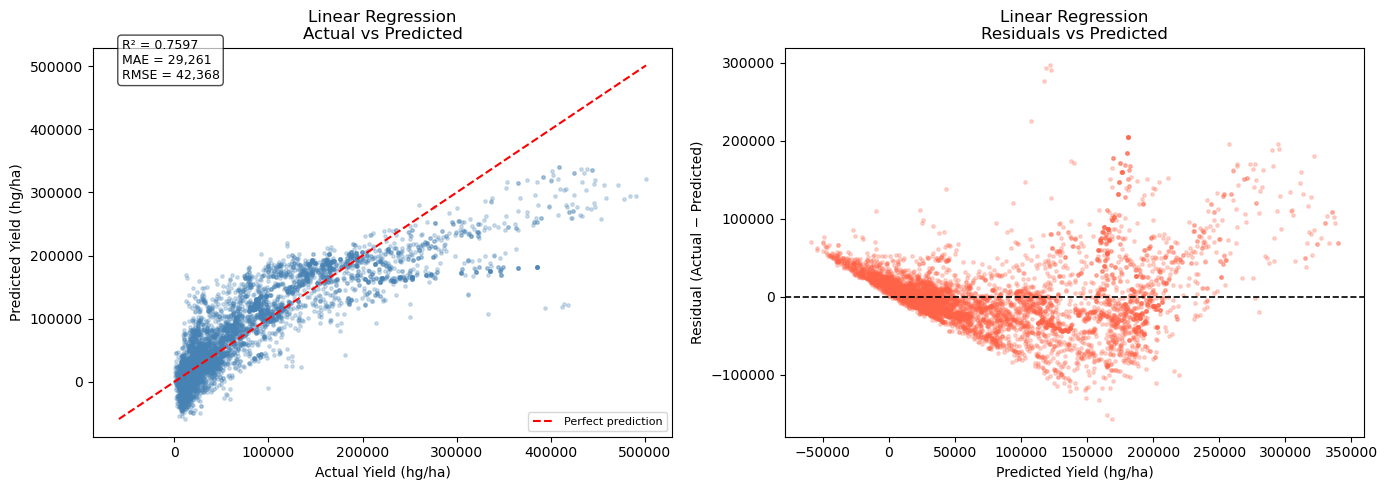

In [10]:
results['Linear Regression'] = plot_regression_model('Linear Regression', y_test, y_pred_lr)

### 5.2 — Polynomial Regression (degree 2)

Extends Linear Regression by adding polynomial terms:
$$y = W_1x + W_2x^2 + \ldots + W_nx^n + b$$

`PolynomialFeatures` is applied **only to the 4 numerical columns** (Year, rainfall, pesticides, temperature) to avoid an exponential expansion from the 111 OHE columns.

In [11]:
pf2 = PolynomialFeatures(degree=2, include_bias=False)

x_num_train_poly2 = pf2.fit_transform(x_train[:, n_ohe_cols:])
x_num_test_poly2  = pf2.transform(x_test[:, n_ohe_cols:])
x_train_poly2 = np.concatenate([x_train[:, :n_ohe_cols], x_num_train_poly2], axis=1)
x_test_poly2  = np.concatenate([x_test[:, :n_ohe_cols],  x_num_test_poly2],  axis=1)

lr_poly2 = LinearRegression()
lr_poly2.fit(x_train_poly2, y_train)
y_pred_poly2 = lr_poly2.predict(x_test_poly2)

print(f'Original numerical features : {x_train[:, n_ohe_cols:].shape[1]}')
print(f'After degree-2 expansion    : {x_num_train_poly2.shape[1]}')
print(f'Total features in model     : {x_train_poly2.shape[1]}')

Original numerical features : 4
After degree-2 expansion    : 14
Total features in model     : 125


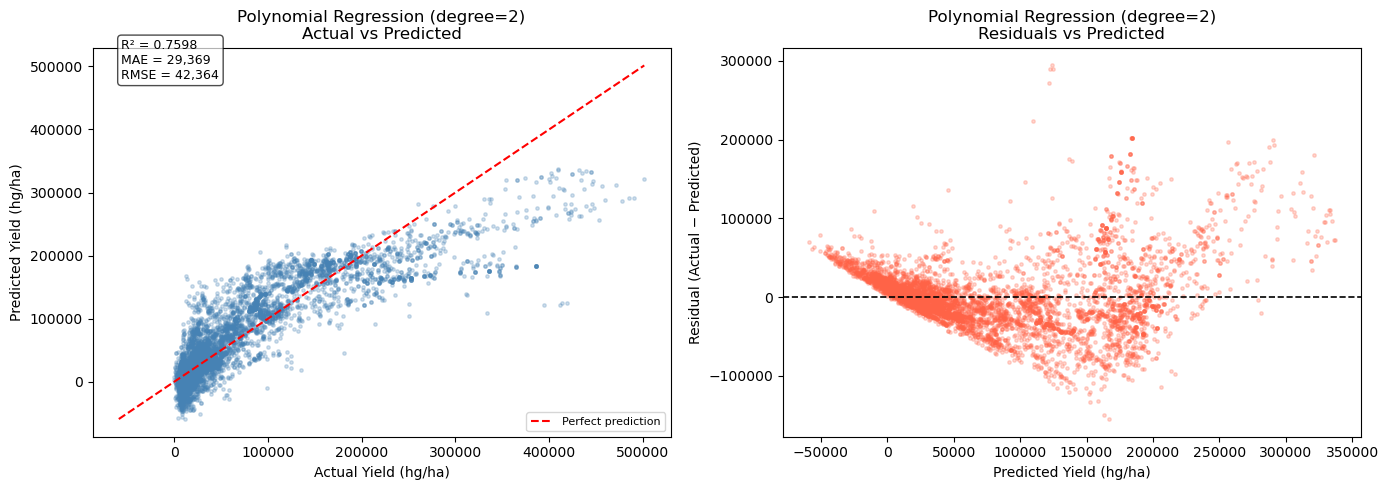

In [12]:
results['Polynomial (deg=2)'] = plot_regression_model('Polynomial Regression (degree=2)', y_test, y_pred_poly2)

### 5.3 — Polynomial Regression (degree 3)

In [13]:
pf3 = PolynomialFeatures(degree=3, include_bias=False)

x_num_train_poly3 = pf3.fit_transform(x_train[:, n_ohe_cols:])
x_num_test_poly3  = pf3.transform(x_test[:, n_ohe_cols:])
x_train_poly3 = np.concatenate([x_train[:, :n_ohe_cols], x_num_train_poly3], axis=1)
x_test_poly3  = np.concatenate([x_test[:, :n_ohe_cols],  x_num_test_poly3],  axis=1)

lr_poly3 = LinearRegression()
lr_poly3.fit(x_train_poly3, y_train)
y_pred_poly3 = lr_poly3.predict(x_test_poly3)

print(f'After degree-3 expansion : {x_num_train_poly3.shape[1]} numerical features')

After degree-3 expansion : 34 numerical features


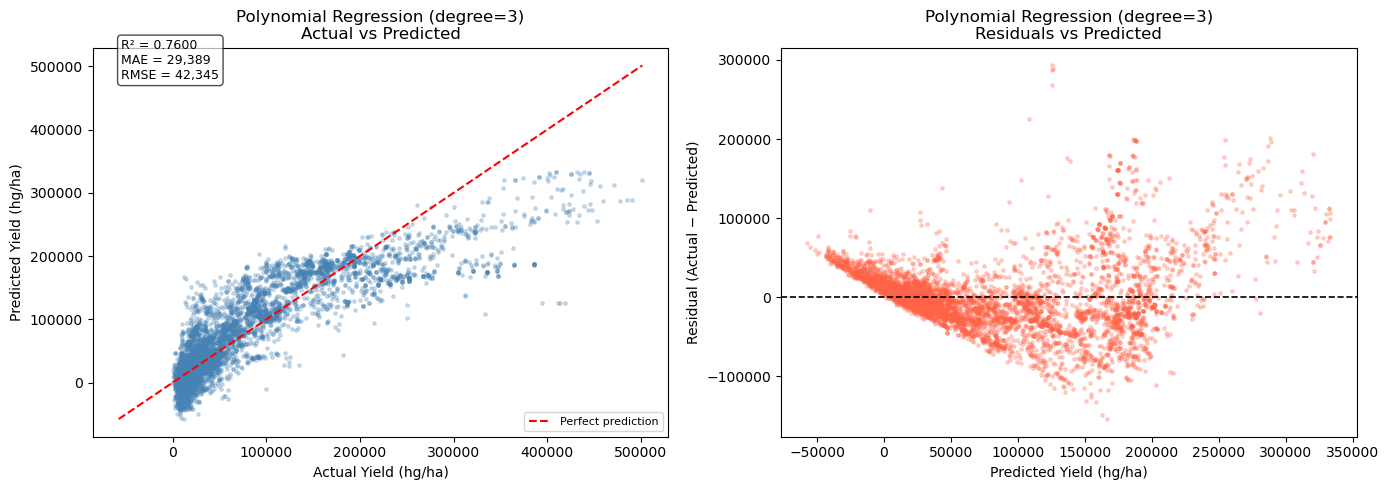

In [14]:
results['Polynomial (deg=3)'] = plot_regression_model('Polynomial Regression (degree=3)', y_test, y_pred_poly3)

### 5.4 — Decision Tree Regressor

Builds a tree of binary decisions based on feature thresholds. Each leaf node returns a constant predicted value.
Naturally handles non-linearity and feature interactions.

In [15]:
dt = DecisionTreeRegressor(random_state=0)
dt.fit(x_train, y_train)
y_pred_dt = dt.predict(x_test)
print('Decision Tree Regressor trained.')

Decision Tree Regressor trained.


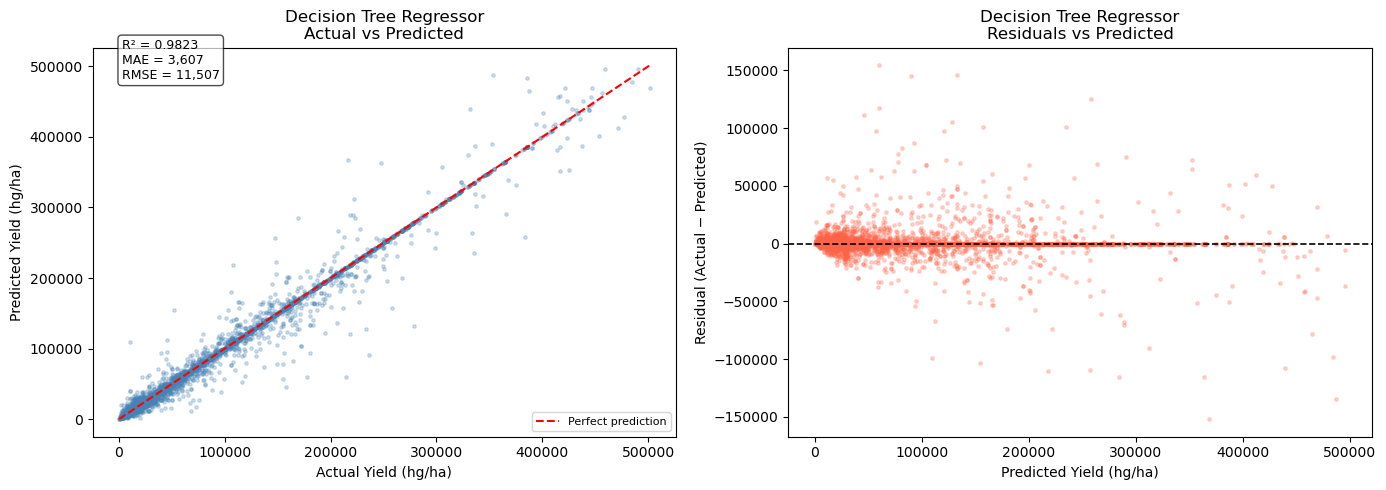

In [16]:
results['Decision Tree'] = plot_regression_model('Decision Tree Regressor', y_test, y_pred_dt)

### 5.5 — Random Forest Regressor

Builds 100 decision trees on random subsets of data (bagging) and averages their predictions.
Reduces variance and overfitting compared to a single decision tree.

In [20]:
rf = RandomForestRegressor(n_estimators=100, random_state=0)
rf.fit(x_train, y_train)
y_pred_rf = rf.predict(x_test)
print('Random Forest Regressor trained (100 trees).')

Random Forest Regressor trained (100 trees).


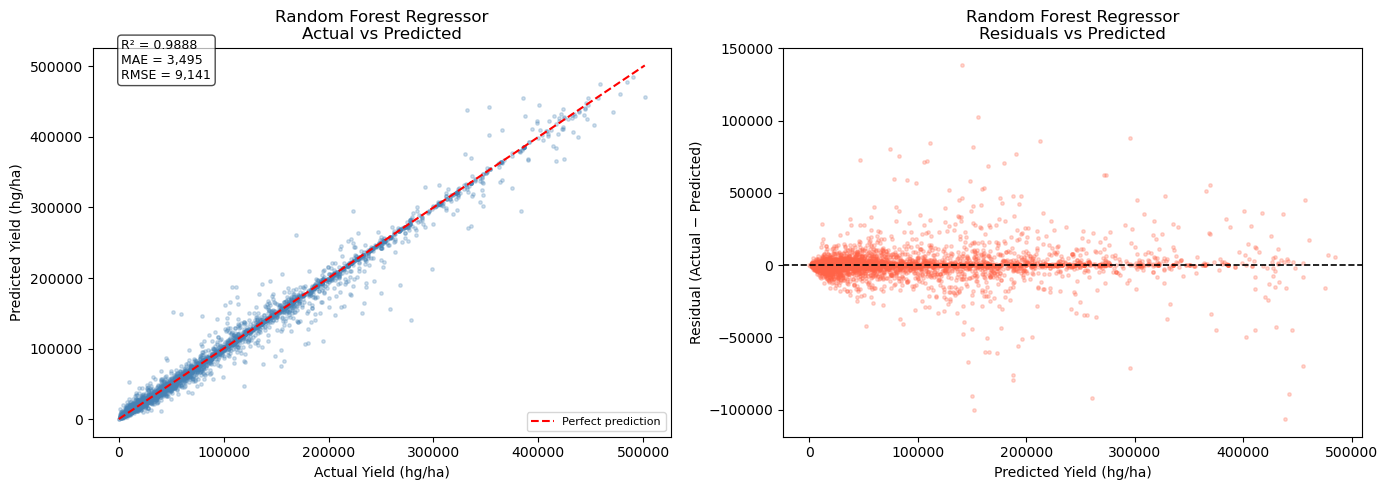

In [21]:
results['Random Forest'] = plot_regression_model('Random Forest Regressor', y_test, y_pred_rf)

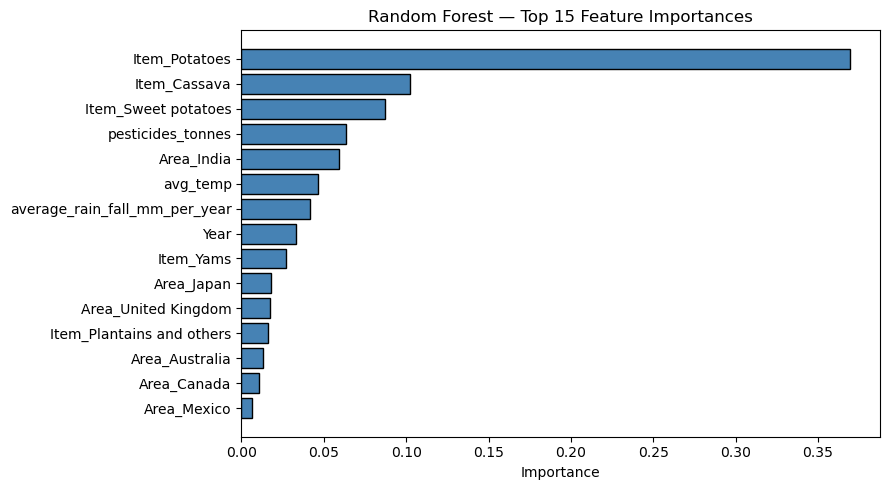

In [24]:
plot_feature_importance(rf, 'Random Forest', all_feat_names, top_n=15)

### 5.6 — Gradient Boosting Regressor

Builds trees **sequentially** — each tree corrects the residual errors of the previous one.
Often achieves performance competitive with Random Forest on tabular data.

In [27]:
gb = GradientBoostingRegressor(random_state=0)
gb.fit(x_train, y_train)
y_pred_gb = gb.predict(x_test)
print('Gradient Boosting Regressor trained.')

Gradient Boosting Regressor trained.


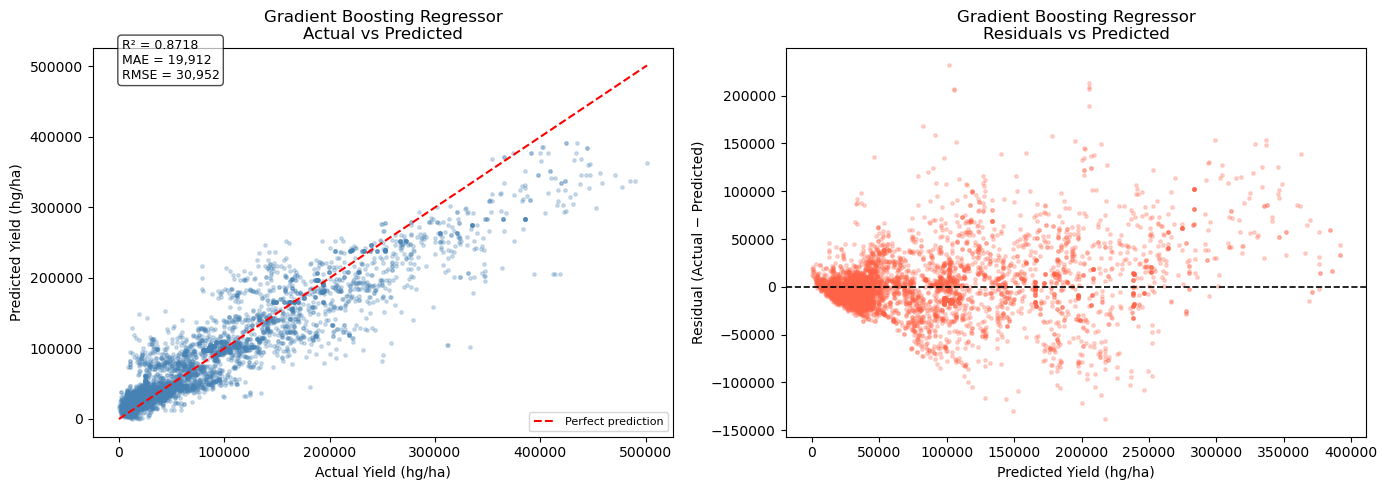

In [28]:
results['Gradient Boosting'] = plot_regression_model('Gradient Boosting Regressor', y_test, y_pred_gb)

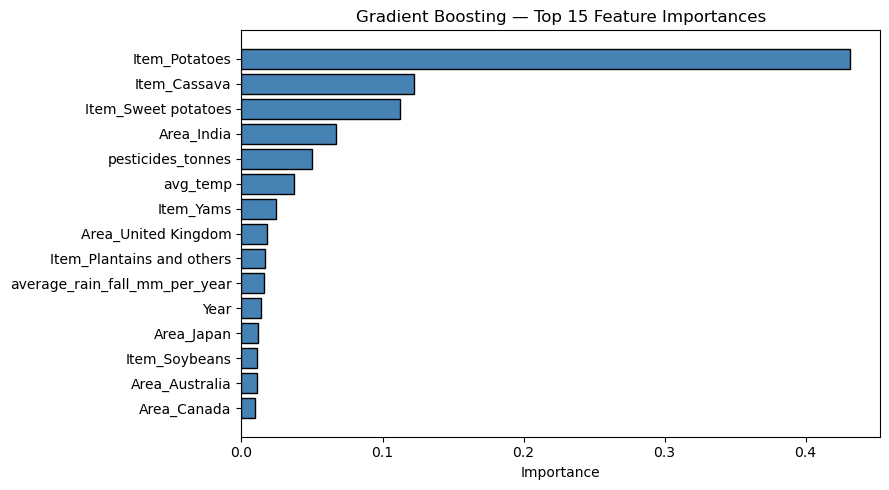

In [29]:
plot_feature_importance(gb, 'Gradient Boosting', all_feat_names, top_n=15)

### 5.7 — Support Vector Regression (SVR)

Uses a RBF kernel to fit a hyperplane in a high-dimensional space with an ε-insensitive loss.
Robust to outliers.

> **Note:** SVR with RBF kernel has quadratic complexity. Training on 22k samples may take several minutes.

In [30]:
svr = SVR(kernel='rbf')
svr.fit(x_train, y_train)
y_pred_svr = svr.predict(x_test)
print('SVR (RBF) trained.')

SVR (RBF) trained.


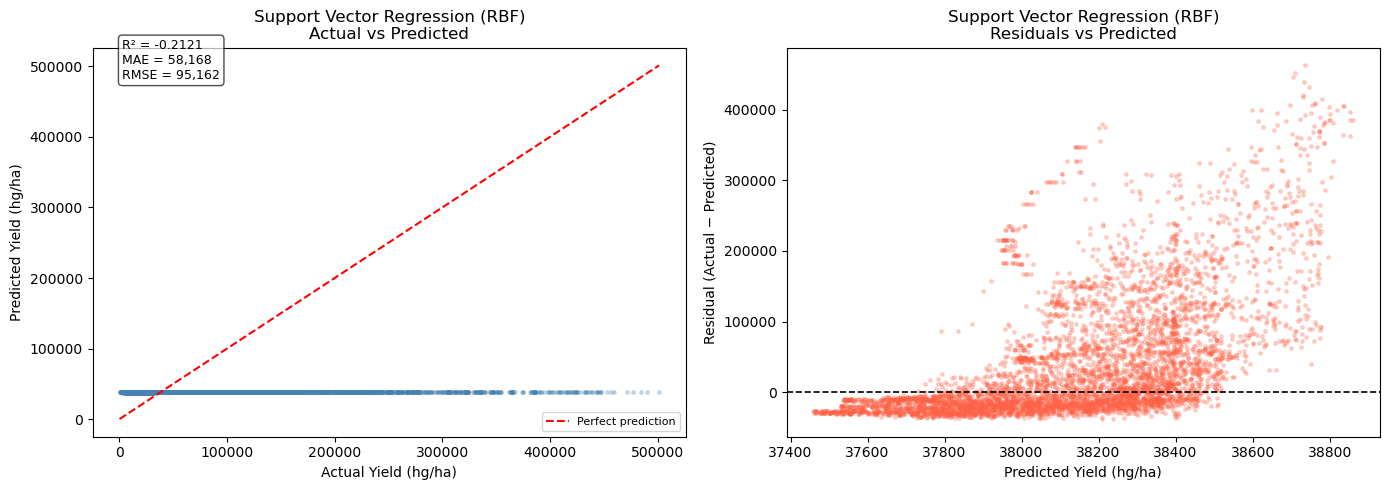

In [31]:
results['SVR (RBF)'] = plot_regression_model('Support Vector Regression (RBF)', y_test, y_pred_svr)

### 5.8 — Baseline (Mean Predictor)

Always predicts the training set mean. R² = 0 by construction. All models must beat this.

In [32]:
y_baseline = np.full_like(y_test, fill_value=np.mean(y_train), dtype=float)
results['Baseline (mean)'] = {
    'R2'  : r2_score(y_test, y_baseline),
    'MAE' : mean_absolute_error(y_test, y_baseline),
    'MSE' : mean_squared_error(y_test, y_baseline),
    'RMSE': np.sqrt(mean_squared_error(y_test, y_baseline))
}
print(f'Baseline R²   = {results["Baseline (mean)"]["R2"]:.4f}')
print(f'Baseline RMSE = {results["Baseline (mean)"]["RMSE"]:,.0f} hg/ha')

Baseline R²   = -0.0003
Baseline RMSE = 86,449 hg/ha


## 6 — Regression Model Comparison

### 6.1 — Benchmark Table

In [34]:
df_results = pd.DataFrame(results).T.round(4)
df_results.index.name = 'Model'
df_results = df_results.sort_values('R2', ascending=False)
print('=' * 72)
print(f'{"Model":<28} {"R2":>8} {"MAE":>10} {"MSE":>12} {"RMSE":>10}')
print('=' * 72)
for name, row in df_results.iterrows():
    print(f'{name:<28} {row["R2"]:>8.4f} {row["MAE"]:>10,.0f} {row["MSE"]:>12,.0f} {row["RMSE"]:>10,.0f}')
print('=' * 72)

Model                              R2        MAE          MSE       RMSE
Random Forest                  0.9888      3,495   83,555,501      9,141
Decision Tree                  0.9823      3,607  132,418,420     11,507
Gradient Boosting              0.8718     19,912  958,022,653     30,952
Polynomial (deg=3)             0.7600     29,389 1,793,119,626     42,345
Polynomial (deg=2)             0.7598     29,369 1,794,683,022     42,364
Linear Regression              0.7597     29,261 1,795,064,402     42,368
Baseline (mean)               -0.0003     65,021 7,473,389,006     86,449
SVR (RBF)                     -0.2121     58,168 9,055,715,839     95,162


### 6.2 — R² Score Comparison

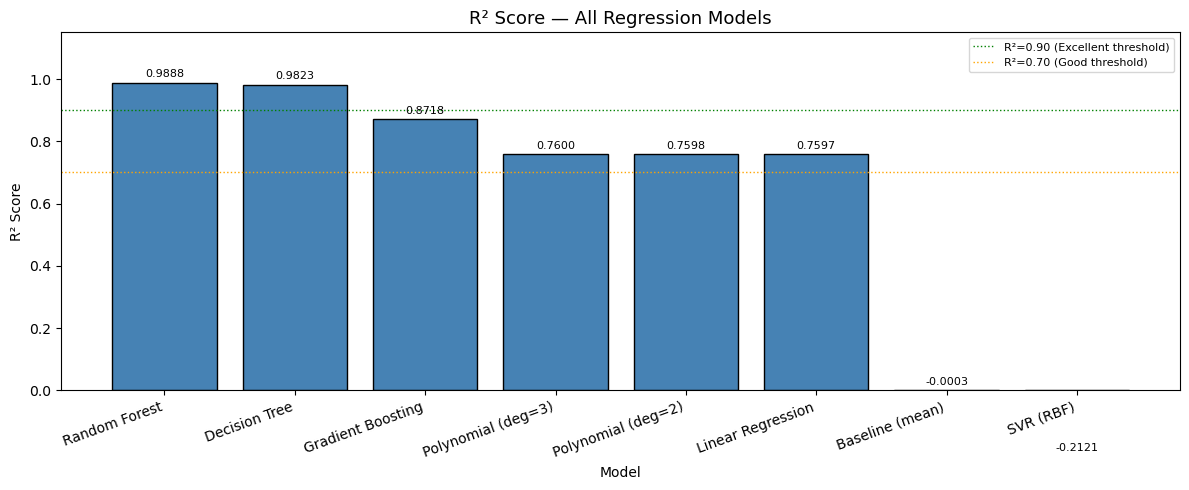

In [35]:
model_names_sorted = df_results.index.tolist()
r2_vals  = df_results['R2'].tolist()
colors_r2 = ['lightgrey' if m == 'Baseline (mean)' else 'steelblue' for m in model_names_sorted]

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(model_names_sorted, r2_vals, color=colors_r2, edgecolor='black')
for bar, val in zip(bars, r2_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.4f}', ha='center', va='bottom', fontsize=8)
ax.set_title('R² Score — All Regression Models', fontsize=13)
ax.set_xlabel('Model')
ax.set_ylabel('R² Score')
ax.set_ylim(0, 1.15)
ax.axhline(0.9, color='green', linestyle=':', linewidth=1, label='R²=0.90 (Excellent threshold)')
ax.axhline(0.7, color='orange', linestyle=':', linewidth=1, label='R²=0.70 (Good threshold)')
ax.legend(fontsize=8)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

### 6.3 — RMSE Comparison (lower is better)

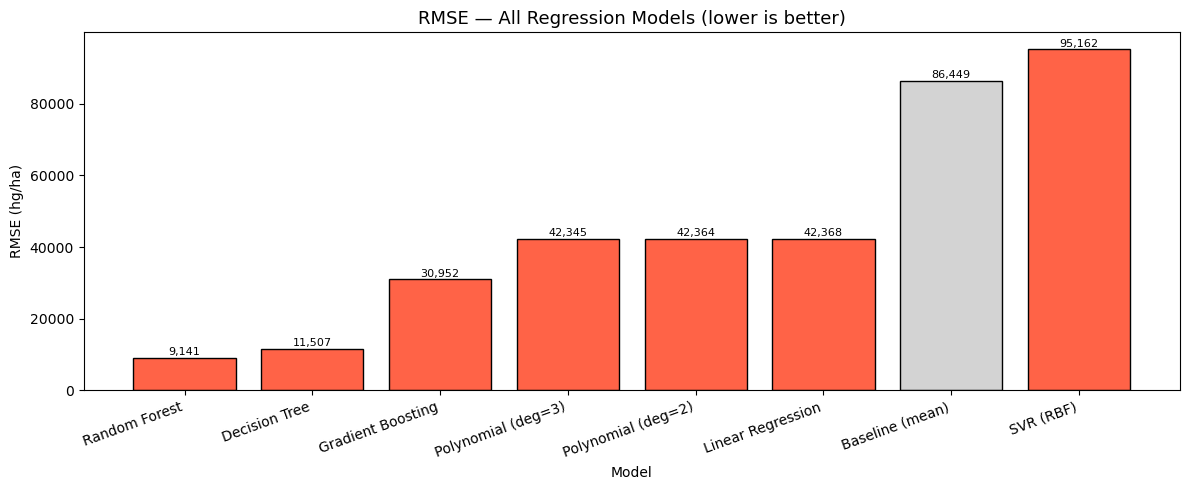

In [36]:
rmse_vals  = df_results['RMSE'].tolist()
colors_rmse = ['lightgrey' if m == 'Baseline (mean)' else 'tomato' for m in model_names_sorted]

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(model_names_sorted, rmse_vals, color=colors_rmse, edgecolor='black')
for bar, val in zip(bars, rmse_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
            f'{val:,.0f}', ha='center', va='bottom', fontsize=8)
ax.set_title('RMSE — All Regression Models (lower is better)', fontsize=13)
ax.set_xlabel('Model')
ax.set_ylabel('RMSE (hg/ha)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

### 6.4 — MAE Comparison (lower is better)

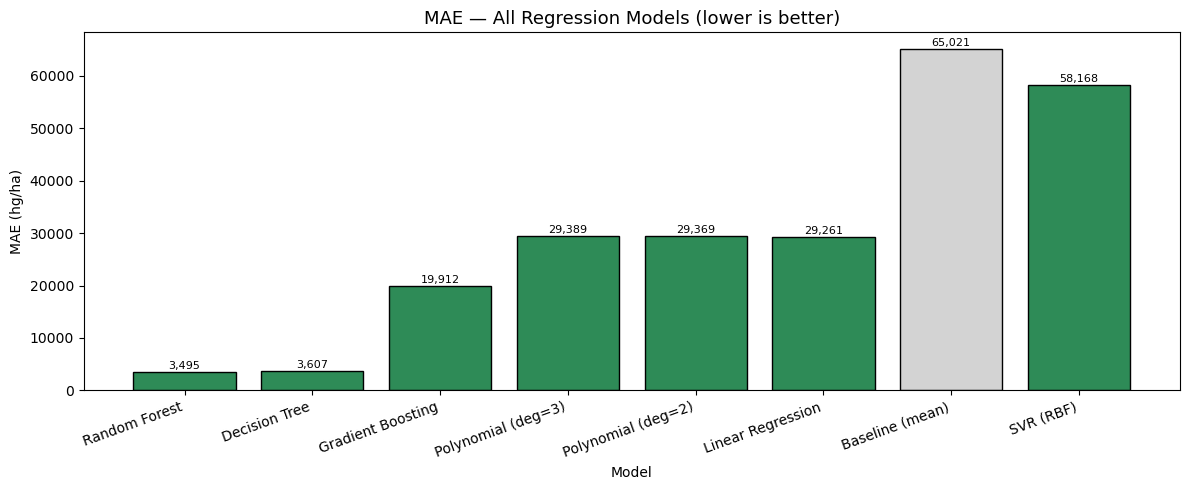

In [37]:
mae_vals   = df_results['MAE'].tolist()
colors_mae = ['lightgrey' if m == 'Baseline (mean)' else 'seagreen' for m in model_names_sorted]

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(model_names_sorted, mae_vals, color=colors_mae, edgecolor='black')
for bar, val in zip(bars, mae_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
            f'{val:,.0f}', ha='center', va='bottom', fontsize=8)
ax.set_title('MAE — All Regression Models (lower is better)', fontsize=13)
ax.set_xlabel('Model')
ax.set_ylabel('MAE (hg/ha)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

### 6.5 — Actual vs Predicted — All Models Side by Side

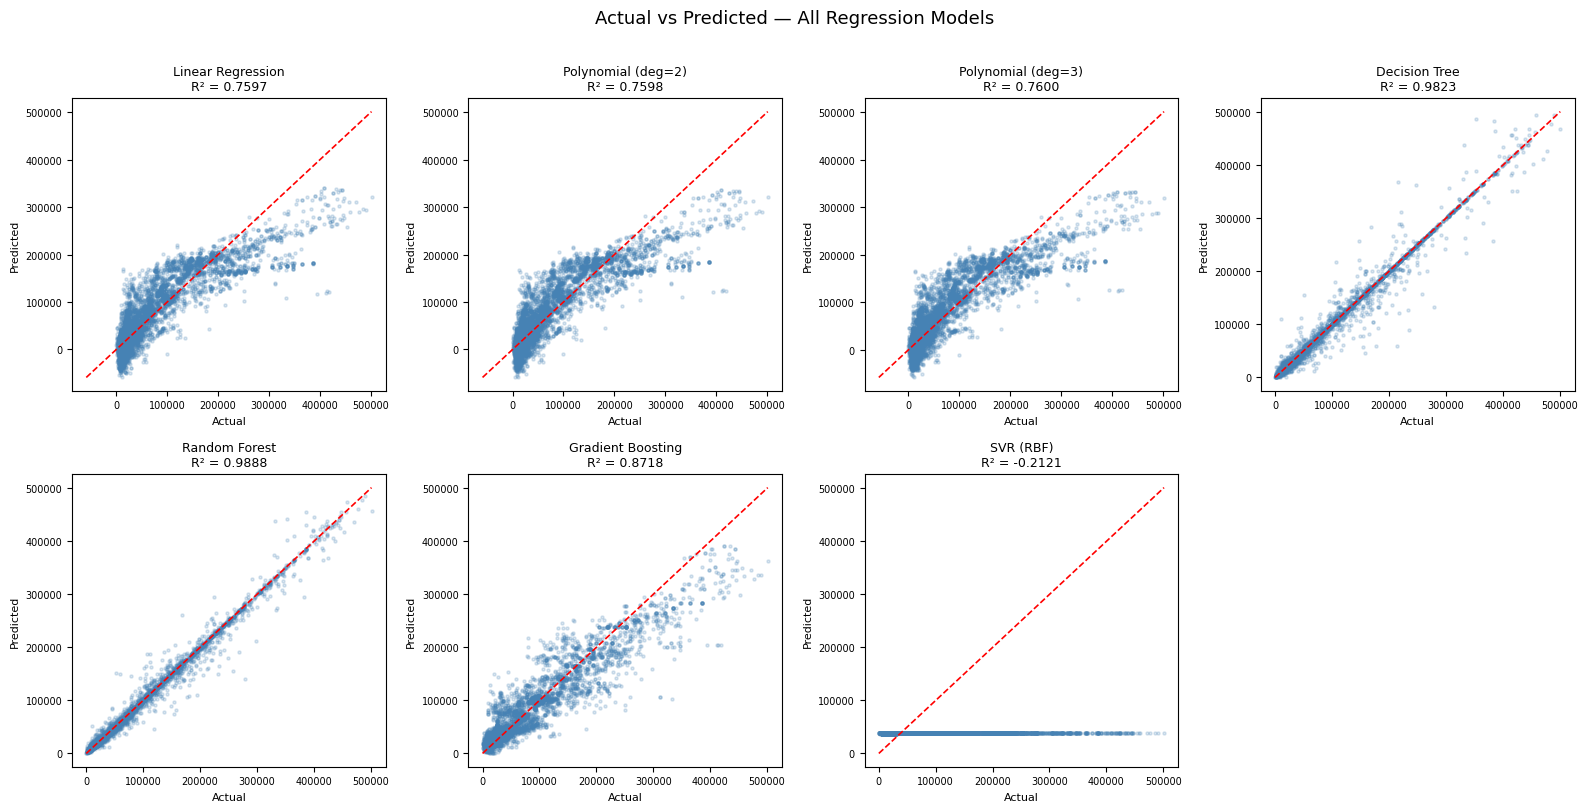

In [38]:
all_preds = {
    'Linear Regression'     : y_pred_lr,
    'Polynomial (deg=2)'    : y_pred_poly2,
    'Polynomial (deg=3)'    : y_pred_poly3,
    'Decision Tree'         : y_pred_dt,
    'Random Forest'         : y_pred_rf,
    'Gradient Boosting'     : y_pred_gb,
    'SVR (RBF)'             : y_pred_svr,
}

n_models = len(all_preds)
ncols = 4
nrows = (n_models + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 4))
axes = axes.flatten()

for ax, (name, y_pred) in zip(axes, all_preds.items()):
    r2 = r2_score(y_test, y_pred)
    ax.scatter(y_test, y_pred, alpha=0.2, color='steelblue', s=5)
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', linewidth=1.2)
    ax.set_title(f'{name}\nR² = {r2:.4f}', fontsize=9)
    ax.set_xlabel('Actual', fontsize=8)
    ax.set_ylabel('Predicted', fontsize=8)
    ax.tick_params(labelsize=7)

# Hide unused axes
for ax in axes[n_models:]:
    ax.set_visible(False)

plt.suptitle('Actual vs Predicted — All Regression Models', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### 6.6 — Best Model Summary

In [39]:
non_baseline = {k: v for k, v in results.items() if k != 'Baseline (mean)'}
best_name    = max(non_baseline, key=lambda m: non_baseline[m]['R2'])
best_r2      = results[best_name]['R2']
best_mae     = results[best_name]['MAE']
best_rmse    = results[best_name]['RMSE']
baseline_mae = results['Baseline (mean)']['MAE']
baseline_rmse= results['Baseline (mean)']['RMSE']

print('=' * 50)
print(f'  Best Regression Model : {best_name}')
print(f'  R²                    = {best_r2:.4f}')
print(f'  MAE                   = {best_mae:,.0f} hg/ha  ({best_mae/10000:.2f} t/ha)')
print(f'  RMSE                  = {best_rmse:,.0f} hg/ha')
print('=' * 50)
print(f'  MAE  reduction vs Baseline : -{(1 - best_mae/baseline_mae)*100:.1f}%')
print(f'  RMSE reduction vs Baseline : -{(1 - best_rmse/baseline_rmse)*100:.1f}%')
print('=' * 50)

if best_r2 > 0.9:
    print(f'  R² = {best_r2:.4f} → EXCELLENT: explains {best_r2*100:.1f}% of yield variance.')
elif best_r2 > 0.7:
    print(f'  R² = {best_r2:.4f} → GOOD: explains {best_r2*100:.1f}% of yield variance.')
else:
    print(f'  R² = {best_r2:.4f} → AVERAGE: only {best_r2*100:.1f}% of variance explained.')

  Best Regression Model : Random Forest
  R²                    = 0.9888
  MAE                   = 3,495 hg/ha  (0.35 t/ha)
  RMSE                  = 9,141 hg/ha
  MAE  reduction vs Baseline : -94.6%
  RMSE reduction vs Baseline : -89.4%
  R² = 0.9888 → EXCELLENT: explains 98.9% of yield variance.


---
## 7 — Classification

The continuous `hg/ha_yield` is converted into **discrete categories** so that classification algorithms can be applied.

Two target types:
- **Binary**: 0 = below average yield, 1 = above average yield
- **3-class**: 0 = low, 1 = medium, 2 = high (based on 33rd and 67th percentiles)

### 7.1 — Classification Preprocessing

In [40]:
# ── Binary target ──
threshold = data['hg/ha_yield'].mean()
y_binary  = (data['hg/ha_yield'] >= threshold).astype(int).values
print(f'Binary threshold (mean) : {threshold:,.0f} hg/ha')
print(f'Class 0 (below avg)     : {(y_binary == 0).sum():,} samples ({(y_binary==0).mean()*100:.1f}%)')
print(f'Class 1 (above avg)     : {(y_binary == 1).sum():,} samples ({(y_binary==1).mean()*100:.1f}%)')

# ── 3-class target ──
q33 = data['hg/ha_yield'].quantile(0.33)
q67 = data['hg/ha_yield'].quantile(0.67)
y_3class = pd.cut(
    data['hg/ha_yield'],
    bins=[-np.inf, q33, q67, np.inf],
    labels=[0, 1, 2]
).astype(int).values
print(f'\n3-class boundaries: Low < {q33:,.0f} | {q33:,.0f} ≤ Medium ≤ {q67:,.0f} | High > {q67:,.0f}')
for cls, lbl in zip([0, 1, 2], ['Low', 'Medium', 'High']):
    print(f'  Class {cls} ({lbl:<6}) : {(y_3class == cls).sum():,} samples')

Binary threshold (mean) : 77,053 hg/ha
Class 0 (below avg)     : 18,617 samples (65.9%)
Class 1 (above avg)     : 9,625 samples (34.1%)

3-class boundaries: Low < 24,510 | 24,510 ≤ Medium ≤ 80,595 | High > 80,595
  Class 0 (Low   ) : 9,320 samples
  Class 1 (Medium) : 9,602 samples
  Class 2 (High  ) : 9,320 samples


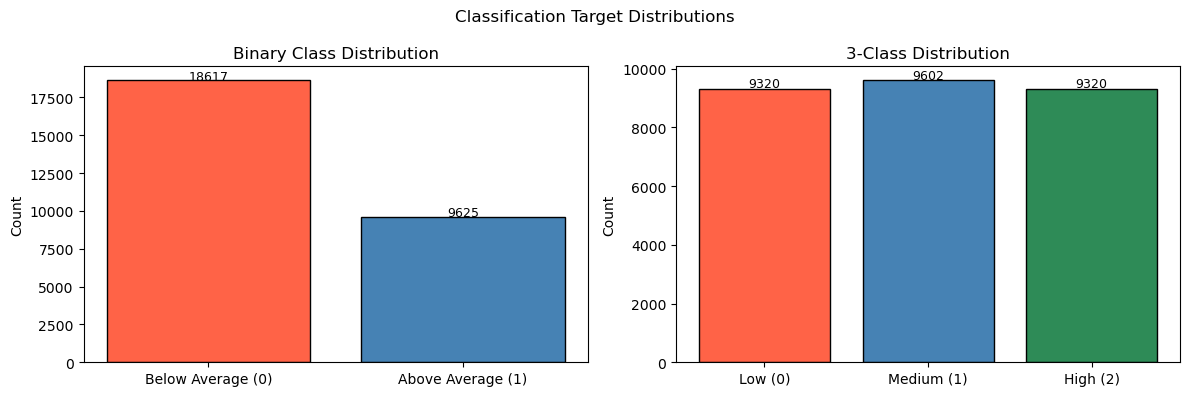

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Binary
binary_counts = pd.Series(y_binary).value_counts().sort_index()
axes[0].bar(['Below Average (0)', 'Above Average (1)'], binary_counts.values,
            color=['tomato', 'steelblue'], edgecolor='black')
for i, v in enumerate(binary_counts.values):
    axes[0].text(i, v + 50, str(v), ha='center', fontsize=9)
axes[0].set_title('Binary Class Distribution')
axes[0].set_ylabel('Count')

# 3-class
_3class_counts = pd.Series(y_3class).value_counts().sort_index()
axes[1].bar(['Low (0)', 'Medium (1)', 'High (2)'], _3class_counts.values,
            color=['tomato', 'steelblue', 'seagreen'], edgecolor='black')
for i, v in enumerate(_3class_counts.values):
    axes[1].text(i, v + 50, str(v), ha='center', fontsize=9)
axes[1].set_title('3-Class Distribution')
axes[1].set_ylabel('Count')

plt.suptitle('Classification Target Distributions', fontsize=12)
plt.tight_layout()
plt.show()

In [42]:
# ── Train/Test split for classification (75/25) ──
# Reuse the same encoded x from regression preprocessing
x_train_b, x_test_b, y_train_b, y_test_b = train_test_split(
    x, y_binary, test_size=0.25, random_state=0
)
x_train_3, x_test_3, y_train_3, y_test_3 = train_test_split(
    x, y_3class, test_size=0.25, random_state=0
)

# Feature scaling for classification sets
sc_b = StandardScaler()
x_train_b[:, n_ohe_cols:] = sc_b.fit_transform(x_train_b[:, n_ohe_cols:])
x_test_b[:, n_ohe_cols:]  = sc_b.transform(x_test_b[:, n_ohe_cols:])

sc_3 = StandardScaler()
x_train_3[:, n_ohe_cols:] = sc_3.fit_transform(x_train_3[:, n_ohe_cols:])
x_test_3[:, n_ohe_cols:]  = sc_3.transform(x_test_3[:, n_ohe_cols:])

print(f'Binary    — Train: {x_train_b.shape[0]:,} | Test: {x_test_b.shape[0]:,}')
print(f'3-Class   — Train: {x_train_3.shape[0]:,} | Test: {x_test_3.shape[0]:,}')

Binary    — Train: 21,181 | Test: 7,061
3-Class   — Train: 21,181 | Test: 7,061


### 7.2 — Classification Helper Function

In [43]:
def plot_confusion_matrix(cm, class_names, model_name, ax):
    """Heatmap of a confusion matrix on a given axes."""
    im = ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(len(class_names)))
    ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names, fontsize=8, rotation=15)
    ax.set_yticklabels(class_names, fontsize=8)
    ax.set_title(model_name, fontsize=10)
    ax.set_xlabel('Predicted', fontsize=8)
    ax.set_ylabel('Actual', fontsize=8)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=9,
                    color='white' if cm[i, j] > cm.max()/2 else 'black')
    return im


def evaluate_classifier(clf, x_test, y_test, average='binary'):
    y_pred = clf.predict(x_test)
    return {
        'Accuracy' : accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average=average, zero_division=0),
        'Recall'   : recall_score(y_test, y_pred, average=average, zero_division=0),
        'CM'       : confusion_matrix(y_test, y_pred)
    }

print('Classification helper functions defined.')

Classification helper functions defined.


---
### 7.3 — Binary Classification (Above / Below Average Yield)

**Logistic Regression**, **KNN**, and **Naive Bayes** trained to predict whether yield is above or below average.

#### 7.3.1 — Logistic Regression

Applies a sigmoid to a linear combination of features:
$$\sigma(z) = \frac{1}{1+e^{-z}}$$
Predicts class 1 if $\sigma(z) \geq 0.5$.

In [44]:
logr = LogisticRegression(max_iter=1000, random_state=0)
logr.fit(x_train_b, y_train_b)
metrics_logr_b = evaluate_classifier(logr, x_test_b, y_test_b, average='binary')

print('Logistic Regression (Binary):')
print(f'  Accuracy  = {metrics_logr_b["Accuracy"]:.4f}')
print(f'  Precision = {metrics_logr_b["Precision"]:.4f}')
print(f'  Recall    = {metrics_logr_b["Recall"]:.4f}')

Logistic Regression (Binary):
  Accuracy  = 0.9499
  Precision = 0.9363
  Recall    = 0.9154


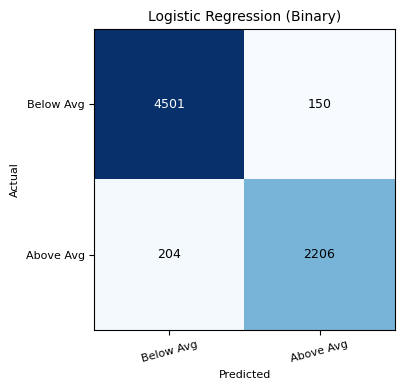

In [45]:
fig, ax = plt.subplots(figsize=(5, 4))
plot_confusion_matrix(metrics_logr_b['CM'], ['Below Avg', 'Above Avg'],
                      'Logistic Regression (Binary)', ax)
plt.tight_layout()
plt.show()

#### 7.3.2 — K-Nearest Neighbors (k=5)

Classifies by majority vote among the 5 nearest neighbours in feature space (Euclidean distance).

In [46]:
knn = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)
knn.fit(x_train_b, y_train_b)
metrics_knn_b = evaluate_classifier(knn, x_test_b, y_test_b, average='binary')

print('KNN k=5 (Binary):')
print(f'  Accuracy  = {metrics_knn_b["Accuracy"]:.4f}')
print(f'  Precision = {metrics_knn_b["Precision"]:.4f}')
print(f'  Recall    = {metrics_knn_b["Recall"]:.4f}')

KNN k=5 (Binary):
  Accuracy  = 0.9867
  Precision = 0.9825
  Recall    = 0.9784


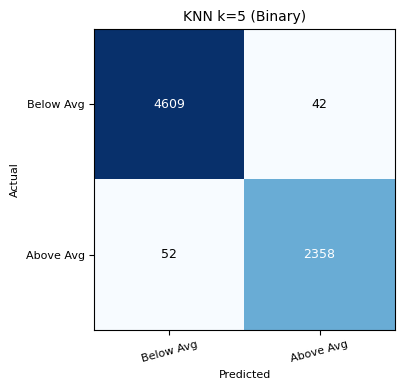

In [47]:
fig, ax = plt.subplots(figsize=(5, 4))
plot_confusion_matrix(metrics_knn_b['CM'], ['Below Avg', 'Above Avg'],
                      'KNN k=5 (Binary)', ax)
plt.tight_layout()
plt.show()

#### 7.3.3 — Naive Bayes (GaussianNB)

Probabilistic classifier using Bayes' theorem with the independence assumption:
$$P(C|X) = \frac{P(X|C) \cdot P(C)}{P(X)}$$

In [48]:
nb = GaussianNB()
nb.fit(x_train_b, y_train_b)
metrics_nb_b = evaluate_classifier(nb, x_test_b, y_test_b, average='binary')

print('Naive Bayes (Binary):')
print(f'  Accuracy  = {metrics_nb_b["Accuracy"]:.4f}')
print(f'  Precision = {metrics_nb_b["Precision"]:.4f}')
print(f'  Recall    = {metrics_nb_b["Recall"]:.4f}')

Naive Bayes (Binary):
  Accuracy  = 0.8133
  Precision = 0.6719
  Recall    = 0.8855


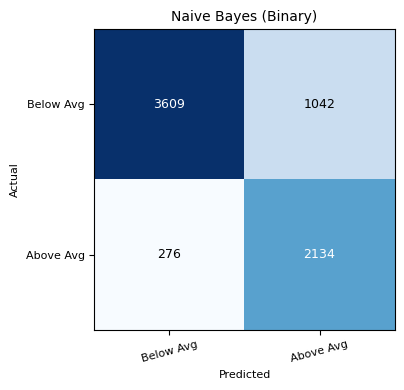

In [49]:
fig, ax = plt.subplots(figsize=(5, 4))
plot_confusion_matrix(metrics_nb_b['CM'], ['Below Avg', 'Above Avg'],
                      'Naive Bayes (Binary)', ax)
plt.tight_layout()
plt.show()

#### 7.3.4 — Binary Classifiers Comparison

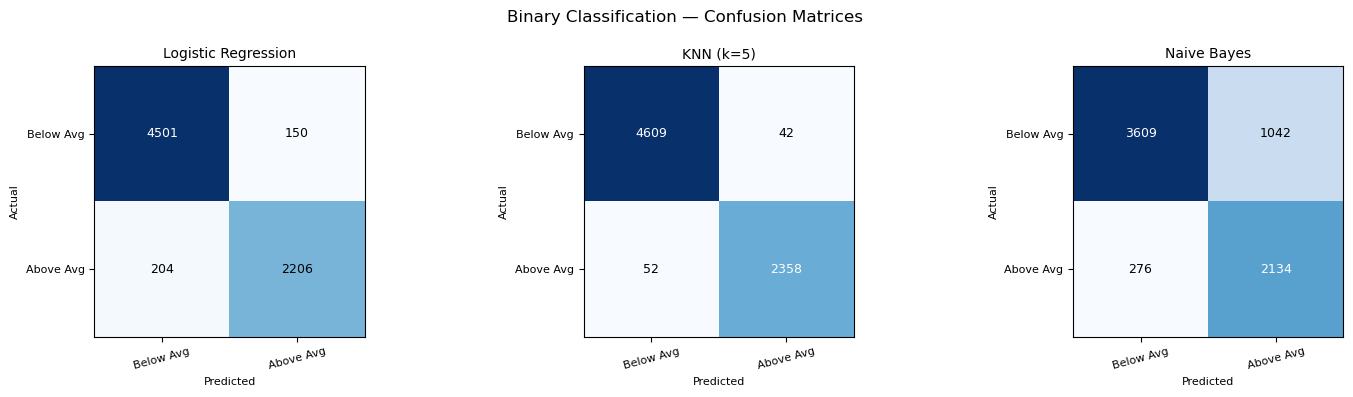

In [50]:
clf_binary = {
    'Logistic Regression': metrics_logr_b,
    'KNN (k=5)'          : metrics_knn_b,
    'Naive Bayes'        : metrics_nb_b,
}

# All confusion matrices side by side
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, metrics) in zip(axes, clf_binary.items()):
    plot_confusion_matrix(metrics['CM'], ['Below Avg', 'Above Avg'], name, ax)
plt.suptitle('Binary Classification — Confusion Matrices', fontsize=12)
plt.tight_layout()
plt.show()

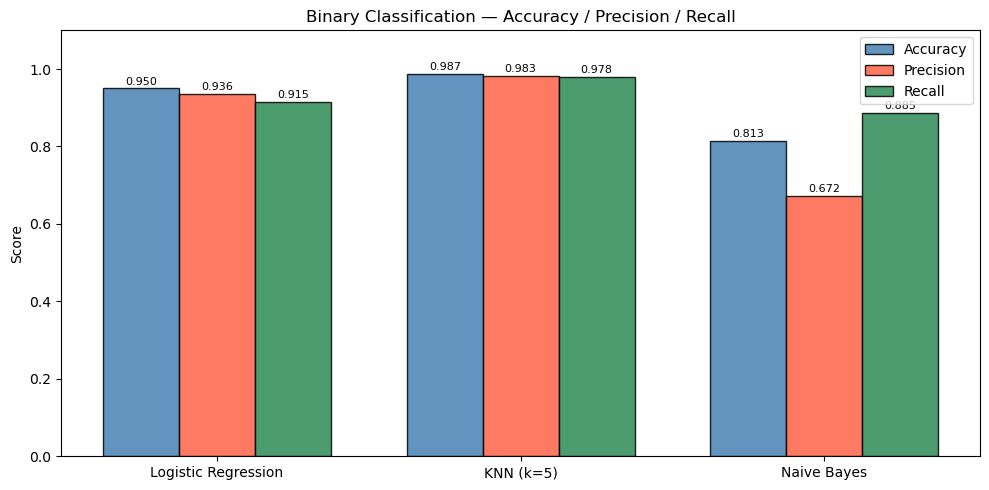

In [51]:
clf_names_b   = list(clf_binary.keys())
metric_labels = ['Accuracy', 'Precision', 'Recall']
metric_colors = ['steelblue', 'tomato', 'seagreen']

x_pos = np.arange(len(clf_names_b))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 5))
for i, (metric, color) in enumerate(zip(metric_labels, metric_colors)):
    vals = [clf_binary[m][metric] for m in clf_names_b]
    bars = ax.bar(x_pos + i*width, vals, width, label=metric, color=color, edgecolor='black', alpha=0.85)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x_pos + width)
ax.set_xticklabels(clf_names_b)
ax.set_ylim(0, 1.1)
ax.set_title('Binary Classification — Accuracy / Precision / Recall', fontsize=12)
ax.set_ylabel('Score')
ax.legend()
plt.tight_layout()
plt.show()

---
### 7.4 — 3-Class Classification (Low / Medium / High Yield)

Same three classifiers, now predicting one of three yield categories.

In [52]:
logr3 = LogisticRegression(max_iter=1000, random_state=0)
logr3.fit(x_train_3, y_train_3)
metrics_logr3 = evaluate_classifier(logr3, x_test_3, y_test_3, average='weighted')

knn3 = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)
knn3.fit(x_train_3, y_train_3)
metrics_knn3 = evaluate_classifier(knn3, x_test_3, y_test_3, average='weighted')

nb3 = GaussianNB()
nb3.fit(x_train_3, y_train_3)
metrics_nb3 = evaluate_classifier(nb3, x_test_3, y_test_3, average='weighted')

clf_3class = {
    'Logistic Regression': metrics_logr3,
    'KNN (k=5)'          : metrics_knn3,
    'Naive Bayes'        : metrics_nb3,
}

print('3-Class Classification Results:')
print(f'{"Model":<22} {"Accuracy":>10} {"Precision":>10} {"Recall":>10}')
print('-' * 55)
for name, m in clf_3class.items():
    print(f'{name:<22} {m["Accuracy"]:>10.4f} {m["Precision"]:>10.4f} {m["Recall"]:>10.4f}')

3-Class Classification Results:
Model                    Accuracy  Precision     Recall
-------------------------------------------------------
Logistic Regression        0.8387     0.8386     0.8387
KNN (k=5)                  0.9541     0.9542     0.9541
Naive Bayes                0.6162     0.6629     0.6162


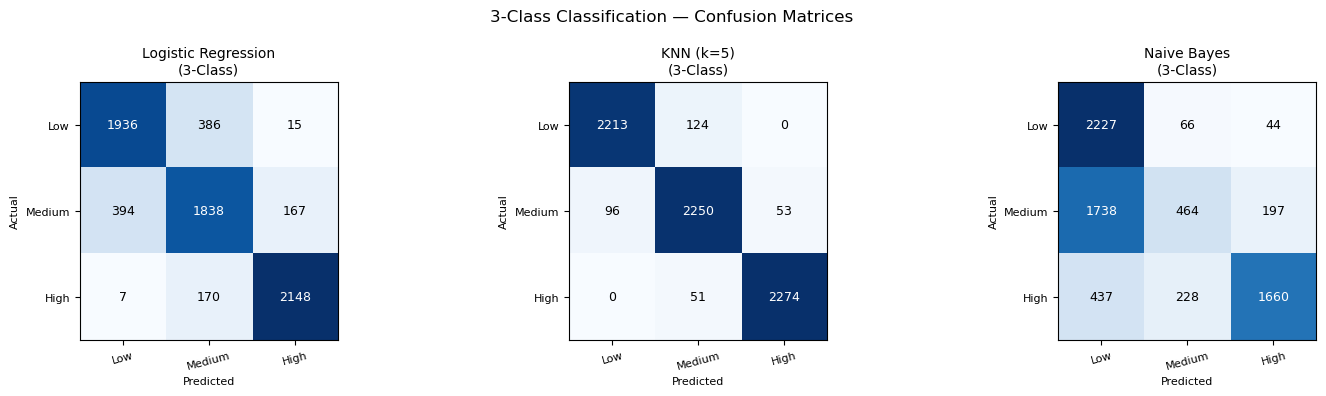

In [53]:
class_names_3 = ['Low', 'Medium', 'High']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, metrics) in zip(axes, clf_3class.items()):
    plot_confusion_matrix(metrics['CM'], class_names_3, f'{name}\n(3-Class)', ax)
plt.suptitle('3-Class Classification — Confusion Matrices', fontsize=12)
plt.tight_layout()
plt.show()

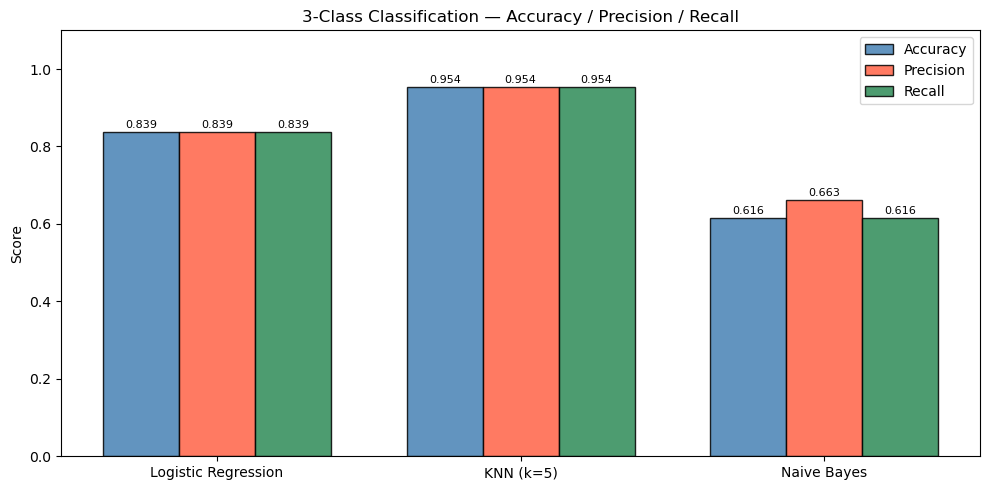

In [54]:
clf_names_3 = list(clf_3class.keys())
x_pos3 = np.arange(len(clf_names_3))

fig, ax = plt.subplots(figsize=(10, 5))
for i, (metric, color) in enumerate(zip(metric_labels, metric_colors)):
    vals3 = [clf_3class[m][metric] for m in clf_names_3]
    bars = ax.bar(x_pos3 + i*width, vals3, width, label=metric, color=color, edgecolor='black', alpha=0.85)
    for bar, val in zip(bars, vals3):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x_pos3 + width)
ax.set_xticklabels(clf_names_3)
ax.set_ylim(0, 1.1)
ax.set_title('3-Class Classification — Accuracy / Precision / Recall', fontsize=12)
ax.set_ylabel('Score')
ax.legend()
plt.tight_layout()
plt.show()

## 8 — Final Summary

### Regression

In [55]:
print('REGRESSION — FINAL BENCHMARK')
print('=' * 72)
print(f'{"Model":<28} {"R2":>8} {"MAE":>10} {"RMSE":>10}')
print('=' * 72)
for name, row in df_results.iterrows():
    marker = ' ← BEST' if name == best_name else ''
    print(f'{name:<28} {row["R2"]:>8.4f} {row["MAE"]:>10,.0f} {row["RMSE"]:>10,.0f}{marker}')
print('=' * 72)

REGRESSION — FINAL BENCHMARK
Model                              R2        MAE       RMSE
Random Forest                  0.9888      3,495      9,141 ← BEST
Decision Tree                  0.9823      3,607     11,507
Gradient Boosting              0.8718     19,912     30,952
Polynomial (deg=3)             0.7600     29,389     42,345
Polynomial (deg=2)             0.7598     29,369     42,364
Linear Regression              0.7597     29,261     42,368
Baseline (mean)               -0.0003     65,021     86,449
SVR (RBF)                     -0.2121     58,168     95,162


### Classification

In [56]:
print('CLASSIFICATION — BINARY (Above / Below Average Yield)')
print('=' * 55)
print(f'{"Model":<22} {"Accuracy":>10} {"Precision":>10} {"Recall":>10}')
print('=' * 55)
best_clf_b = max(clf_binary, key=lambda m: clf_binary[m]['Accuracy'])
for name, m in clf_binary.items():
    marker = ' ← BEST' if name == best_clf_b else ''
    print(f'{name:<22} {m["Accuracy"]:>10.4f} {m["Precision"]:>10.4f} {m["Recall"]:>10.4f}{marker}')
print('=' * 55)

print('\nCLASSIFICATION — 3-CLASS (Low / Medium / High Yield)')
print('=' * 55)
print(f'{"Model":<22} {"Accuracy":>10} {"Precision":>10} {"Recall":>10}')
print('=' * 55)
best_clf_3 = max(clf_3class, key=lambda m: clf_3class[m]['Accuracy'])
for name, m in clf_3class.items():
    marker = ' ← BEST' if name == best_clf_3 else ''
    print(f'{name:<22} {m["Accuracy"]:>10.4f} {m["Precision"]:>10.4f} {m["Recall"]:>10.4f}{marker}')
print('=' * 55)

CLASSIFICATION — BINARY (Above / Below Average Yield)
Model                    Accuracy  Precision     Recall
Logistic Regression        0.9499     0.9363     0.9154
KNN (k=5)                  0.9867     0.9825     0.9784 ← BEST
Naive Bayes                0.8133     0.6719     0.8855

CLASSIFICATION — 3-CLASS (Low / Medium / High Yield)
Model                    Accuracy  Precision     Recall
Logistic Regression        0.8387     0.8386     0.8387
KNN (k=5)                  0.9541     0.9542     0.9541 ← BEST
Naive Bayes                0.6162     0.6629     0.6162


## 9 — Example Prediction

Using the best regression model to predict yield for a specific scenario, and the best classifier to predict its yield category.

In [57]:
# Example: Albania, Maize, 2005, Rainfall=1485mm, Pesticides=121t, Temp=16.37°C
sample_df = pd.DataFrame({
    'Area'                          : ['Albania'],
    'Item'                          : ['Maize'],
    'Year'                          : [2005],
    'average_rain_fall_mm_per_year' : [1485.0],
    'pesticides_tonnes'             : [121.0],
    'avg_temp'                      : [16.37]
})

# Encode
sample_enc = ct.transform(sample_df)
if hasattr(sample_enc, 'toarray'):
    sample_enc = sample_enc.toarray()
sample_enc = sample_enc.astype(float)
sample_enc[:, n_ohe_cols:] = sc.transform(sample_enc[:, n_ohe_cols:])

# Regression prediction (best model)
best_reg_model_map = {
    'Linear Regression' : lr,
    'Polynomial (deg=2)': lr_poly2,
    'Polynomial (deg=3)': lr_poly3,
    'Decision Tree'     : dt,
    'Random Forest'     : rf,
    'Gradient Boosting' : gb,
    'SVR (RBF)'         : svr,
}
best_reg_model   = best_reg_model_map[best_name]

if best_name in ['Polynomial (deg=2)', 'Polynomial (deg=3)']:
    pf_map = {'Polynomial (deg=2)': pf2, 'Polynomial (deg=3)': pf3}
    pf_best = pf_map[best_name]
    s_ohe  = sample_enc[:, :n_ohe_cols]
    s_poly = pf_best.transform(sample_enc[:, n_ohe_cols:])
    sample_for_pred = np.concatenate([s_ohe, s_poly], axis=1)
else:
    sample_for_pred = sample_enc

prediction   = best_reg_model.predict(sample_for_pred)[0]
avg_yield    = float(np.mean(y_train))

print(f'=== Regression Prediction ({best_name}) ===')
print(f'  Predicted yield : {prediction:,.0f} hg/ha')
print(f'  Equivalent      : {prediction/10000:.2f} tonnes/ha')
print(f'  Training mean   : {avg_yield:,.0f} hg/ha')
if prediction > avg_yield:
    print(f'  → {((prediction-avg_yield)/avg_yield*100):.1f}% ABOVE average')
else:
    print(f'  → {((avg_yield-prediction)/avg_yield*100):.1f}% BELOW average')

# Classification prediction
sample_enc_clf = ct.transform(sample_df)
if hasattr(sample_enc_clf, 'toarray'):
    sample_enc_clf = sample_enc_clf.toarray()
sample_enc_clf = sample_enc_clf.astype(float)
sample_enc_clf[:, n_ohe_cols:] = sc_b.transform(sample_enc_clf[:, n_ohe_cols:])

best_clf_b_model_map = {
    'Logistic Regression': logr,
    'KNN (k=5)'          : knn,
    'Naive Bayes'        : nb,
}
best_clf_b_model = best_clf_b_model_map[best_clf_b]
pred_class_b = best_clf_b_model.predict(sample_enc_clf)[0]
binary_label = 'Above Average' if pred_class_b == 1 else 'Below Average'

print(f'\n=== Classification Prediction ({best_clf_b}) ===')
print(f'  Binary class : {pred_class_b} → {binary_label} yield')

=== Regression Prediction (Random Forest) ===
  Predicted yield : 39,398 hg/ha
  Equivalent      : 3.94 tonnes/ha
  Training mean   : 76,740 hg/ha
  → 48.7% BELOW average

=== Classification Prediction (KNN (k=5)) ===
  Binary class : 0 → Below Average yield
